# 03 — Bespoke CNN

Completed experiment: ten ReLU epochs and ten tanh epochs, with captured outputs.
Reuses the LeNet data, training, checkpoint-selection, and evaluation helpers.
Re-running the training cell below starts BOTH experiments again. To redisplay
existing results without training, use the final results-only section instead.

The hypothesis is that upsampling gives convolutions more spatial room for a
longer descent while channels grow, potentially helping unusual handwriting.
Interpolation adds no information; improvement is unproven. Bilinear interpolation
is the accepted starting default; its accuracy benefit remains unproven.

Two SAME convolutions per stage; activation after each; max pool 2/stride 2 with
ceil mode after every stage. Shape order is channels × height × width:

| Kernel | Both convolution outputs | After pooling |
|---|---|---|
| 10 | 2 × 224 × 224 | 2 × 112 × 112 |
| 9 | 4 × 112 × 112 | 4 × 56 × 56 |
| 8 | 8 × 56 × 56 | 8 × 28 × 28 |
| 7 | 16 × 28 × 28 | 16 × 14 × 14 |
| 6 | 32 × 14 × 14 | 32 × 7 × 7 |
| 5 | 64 × 7 × 7 | 64 × 4 × 4 |
| 4 | 128 × 4 × 4 | 128 × 2 × 2 |
| 3 | 256 × 2 × 2 | 256 × 1 × 1 |

Flatten 256 → linear 10 raw logits. No softmax, batch normalization, or global
average pooling. Even kernels use asymmetric zero padding; late kernels see
substantial padding. Equal epochs/examples do not mean equal runtime versus LeNet.


In [1]:
# Standard imports
from datetime import datetime
from pathlib import Path
import sys
from uuid import uuid4
from zoneinfo import ZoneInfo

# Third-party imports
import hashlib
import platform
import sklearn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Markdown, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

# Local imports
from scripts.dataset.digit_dataset_config import PIXEL_COLUMNS
from scripts.dataset.digit_dataset_helpers import load_datasets
from scripts.model.digit_model_helpers import (
    build_model,
    build_data_loaders,
    inspect_last_validation_prediction,
    plot_training_history,
    seed_training,
    train_model,
)
from scripts.model.digit_model_metrics import (
    build_per_digit_metrics,
    plot_misclassified_digit,
    plot_validation_confusion_matrix,
)


## Matched experiment configuration

In [2]:
# Run both variants with the same initialization, split, batch order, and budget.
ACTIVATIONS = ("relu", "tanh")
UPSAMPLE_MODE = "bilinear"  # Accepted starting default; align_corners=False.
SEED = 42
VALIDATION_FRACTION = 0.2
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 10


In [3]:
datasets = load_datasets()
train = datasets["train"]
test = datasets["test"]
print(f"Training shape: {train.shape}")
print(f"Test shape: {test.shape}")

Training shape: (42000, 785)
Test shape: (28000, 784)


## Inspect shape without training

In [4]:
seed_training(SEED)
model = build_model("bespoke", activation=ACTIVATIONS[0], upsample_mode=UPSAMPLE_MODE)
print(model)
with torch.no_grad():
    print("Output shape:", tuple(model(torch.zeros(1, 1, 28, 28)).shape))


BespokeCNN(
  (resize): Upsample(size=(224, 224), mode='bilinear')
  (stages): ModuleList(
    (0): Sequential(
      (0): Conv2d(1, 2, kernel_size=(10, 10), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): Conv2d(2, 2, kernel_size=(10, 10), stride=(1, 1), padding=same)
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    )
    (1): Sequential(
      (0): Conv2d(2, 4, kernel_size=(9, 9), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): Conv2d(4, 4, kernel_size=(9, 9), stride=(1, 1), padding=same)
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    )
    (2): Sequential(
      (0): Conv2d(4, 8, kernel_size=(8, 8), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): Conv2d(8, 8, kernel_size=(8, 8), stride=(1, 1), padding=same)
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    )
    (3): Sequential(
  

/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


## Train both variants and review the same gauntlet

Each variant starts with a fresh seeded model and loaders. Adam, learning rate,
loss, data, and budget are held fixed. Default convolution initialization is the
same for both activations. No automatic early stopping or tuning is introduced.
Exact cross-device reproducibility is not guaranteed. Existing LeNet artifacts
are untouched. Validation metadata records configuration, versions, data/split
fingerprints, history, and checkpoint pairing.


## Bespoke — ReLU results


Bespoke — relu
Training device: mps
Epoch 01/10 | train loss 2.3020, accuracy 11.08% | val loss 2.3017, accuracy 11.15%
Epoch 02/10 | train loss 2.3016, accuracy 11.15% | val loss 2.3014, accuracy 11.15%
Epoch 03/10 | train loss 2.3015, accuracy 11.10% | val loss 2.3012, accuracy 11.15%
Epoch 04/10 | train loss 2.3015, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Epoch 05/10 | train loss 2.3013, accuracy 11.15% | val loss 2.3014, accuracy 11.15%
Epoch 06/10 | train loss 2.3014, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Epoch 07/10 | train loss 2.3014, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Epoch 08/10 | train loss 2.3013, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Epoch 09/10 | train loss 2.3013, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Epoch 10/10 | train loss 2.3013, accuracy 11.15% | val loss 2.3012, accuracy 11.15%
Restored epoch 9: validation loss 2.3012
Best weights saved to: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/da

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,2.301968,2.301684,0.110804,0.111548
1,2,2.301588,2.301395,0.111518,0.111548
2,3,2.301477,2.301205,0.110982,0.111548
3,4,2.301476,2.301182,0.111518,0.111548
4,5,2.301333,2.301394,0.111518,0.111548
5,6,2.301422,2.301187,0.111518,0.111548
6,7,2.301388,2.301188,0.111518,0.111548
7,8,2.301338,2.301194,0.111518,0.111548
8,9,2.301350,2.301173,0.111518,0.111548
9,10,2.301335,2.301177,0.111518,0.111548


,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
0,827,0,827,0.000000,0.0,0.000000,0.901548
2,835,0,835,0.000000,0.0,0.000000,0.900595
3,870,0,870,0.000000,0.0,0.000000,0.896429
4,814,0,814,0.000000,0.0,0.000000,0.903095
5,759,0,759,0.000000,0.0,0.000000,0.909643
6,827,0,827,0.000000,0.0,0.000000,0.901548
7,880,0,880,0.000000,0.0,0.000000,0.895238
8,813,0,813,0.000000,0.0,0.000000,0.903214
9,838,0,838,0.000000,0.0,0.000000,0.900238


Actual digit 3: 870 misclassified validation images
Actual digit: 1 | Predicted digit: 1


...

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.671994,0.182214,0.768155,0.948333
1,2,0.148177,0.114625,0.956815,0.967857
2,3,0.103636,0.070494,0.970446,0.980000
3,4,0.086531,0.111806,0.974792,0.967857
4,5,0.083811,0.075834,0.975536,0.976310
5,6,0.107420,0.103306,0.969821,0.971786
6,7,0.079555,0.068680,0.977262,0.980000
7,8,0.069887,0.092342,0.978631,0.973571
8,9,0.062961,0.073937,0.981339,0.978690
9,10,0.059538,0.062895,0.982589,0.982262


,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
9,838,810,28,0.984204,0.966587,0.975316,0.995119
3,870,861,9,0.963087,0.989655,0.976190,0.995000
8,813,793,20,0.979012,0.975400,0.977203,0.995595
5,759,734,25,0.994580,0.967062,0.980628,0.996548
4,814,805,9,0.976942,0.988943,0.982906,0.996667
2,835,824,11,0.982122,0.986826,0.984468,0.996905
0,827,805,22,0.996287,0.973398,0.984709,0.997024
7,880,865,15,0.989703,0.982955,0.986317,0.997143
1,937,932,5,0.978992,0.994664,0.986765,0.997024


Actual digit 3: 9 misclassified validation images
Actual digit: 1 | Predicted digit: 1


,Logit,Probability
Digit,,
0,-1.839313,1.062446e-06
1,11.915581,9.999573e-01
2,-0.877427,2.780025e-06
3,-2.772647,4.177969e-07
4,1.219573,2.263418e-05
5,-3.309733,2.441808e-07
6,-0.225951,5.333117e-06
7,-0.460610,4.217648e-06
8,-0.372923,4.604179e-06


### ReLU learning curves and validation images

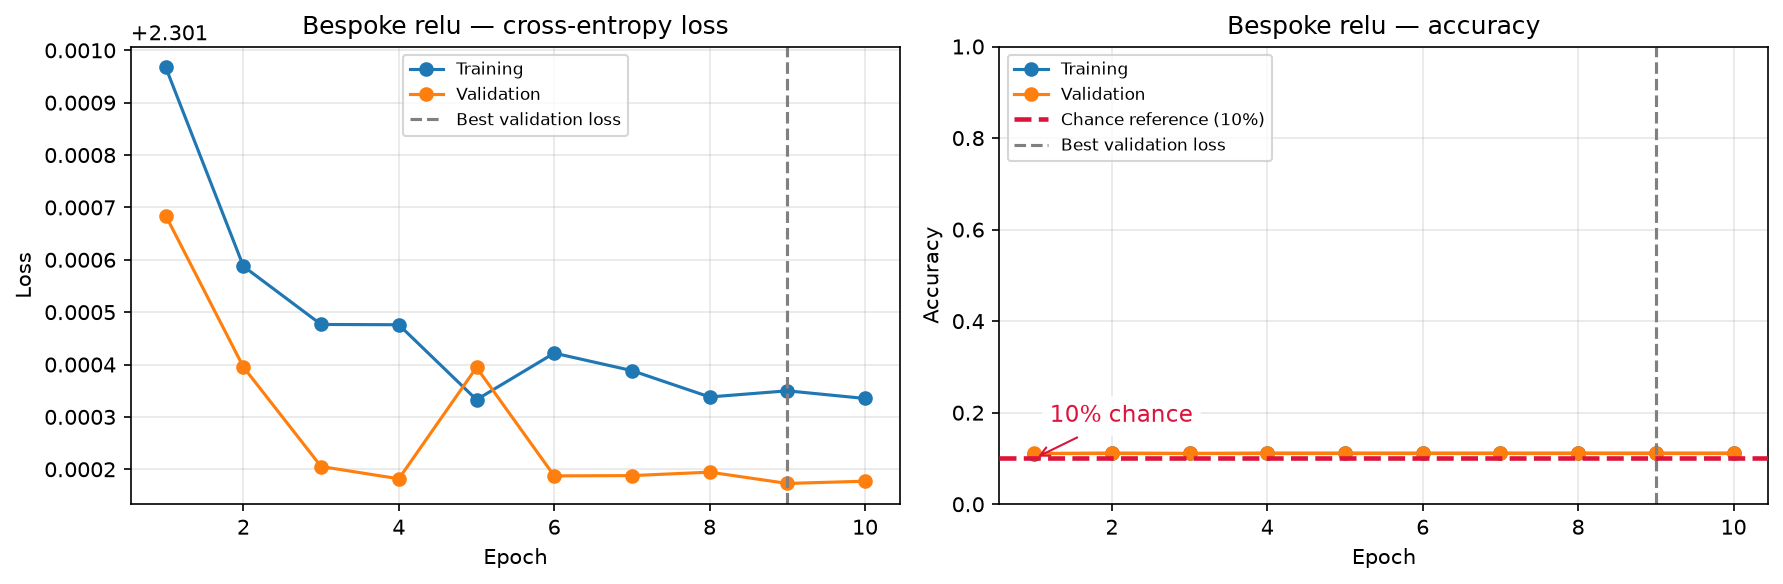

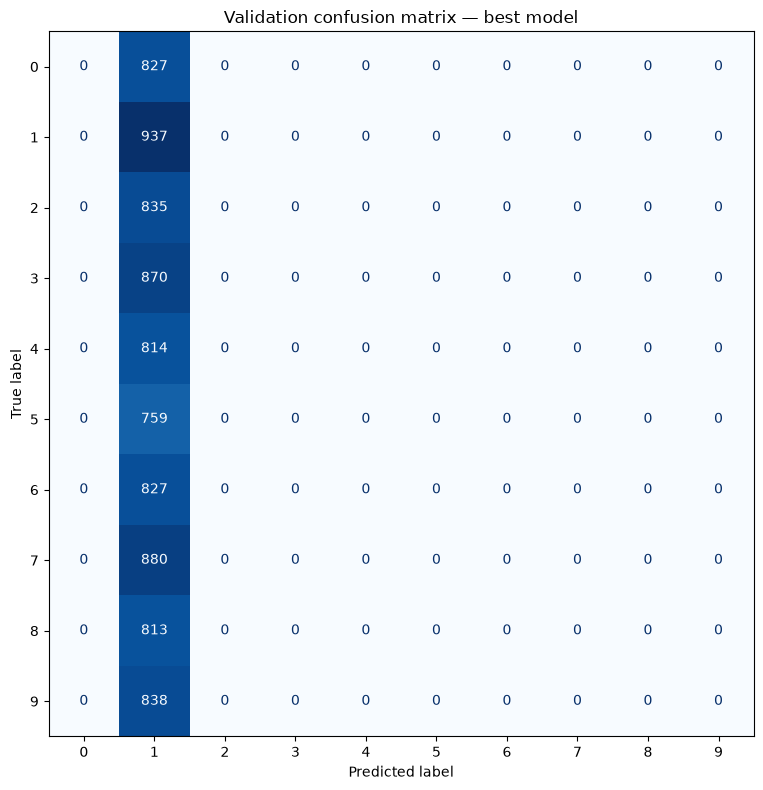

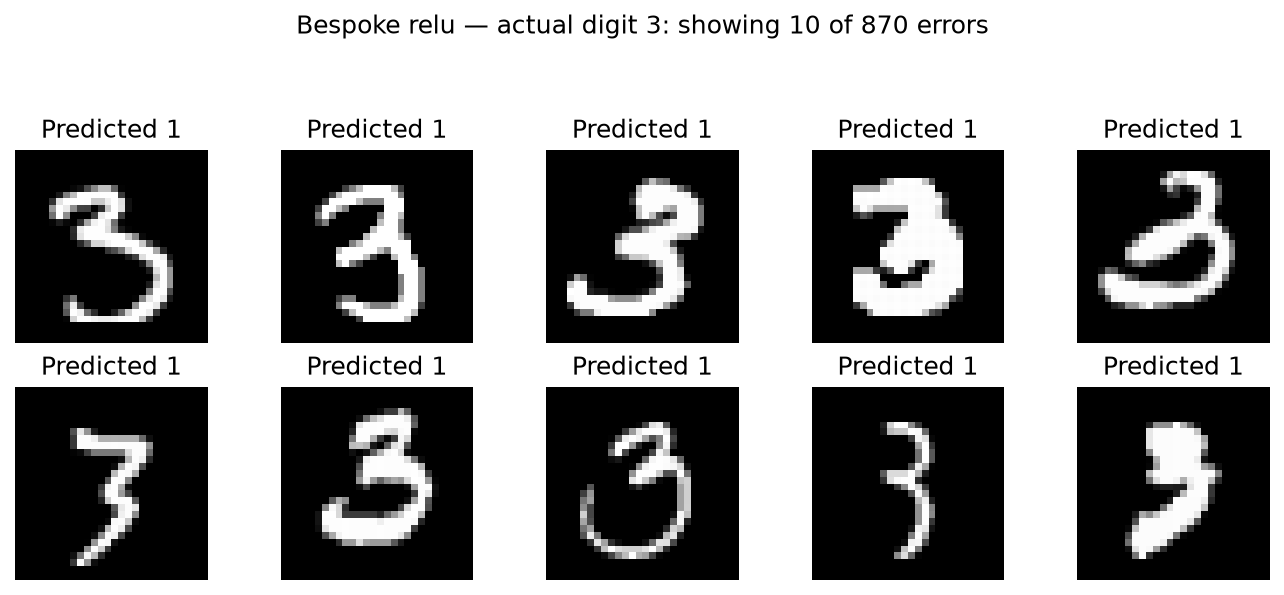

### Tanh learning curves and validation images

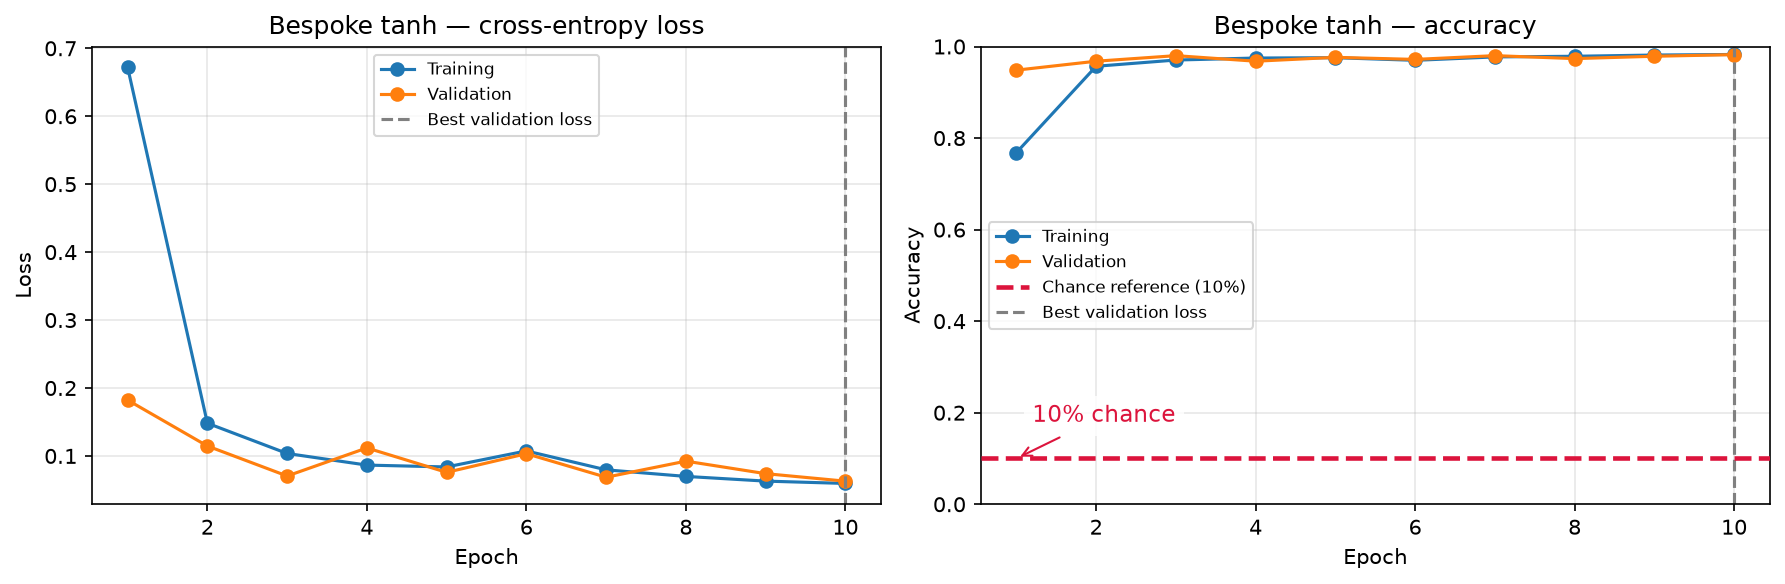

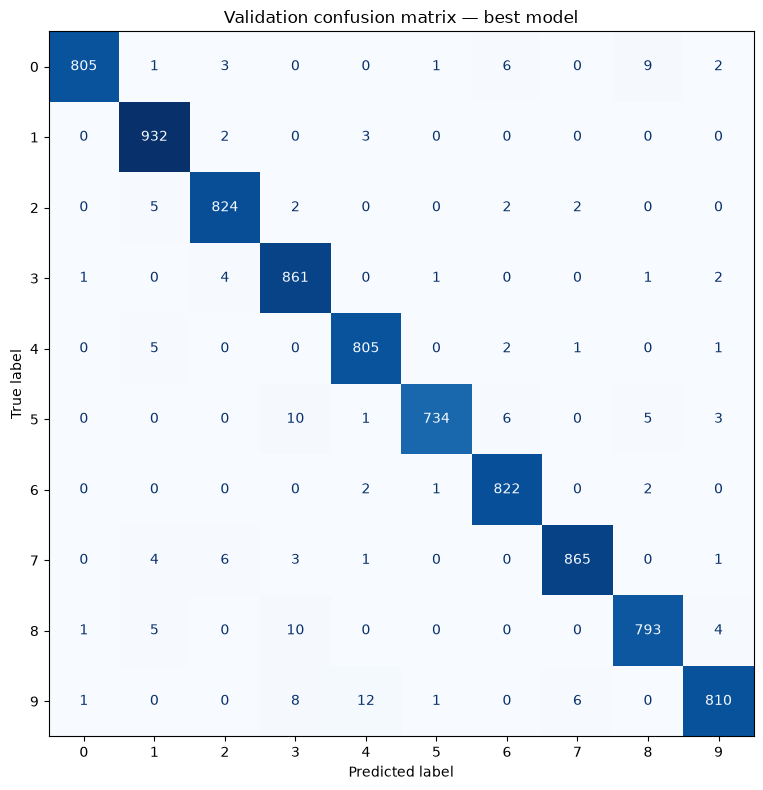

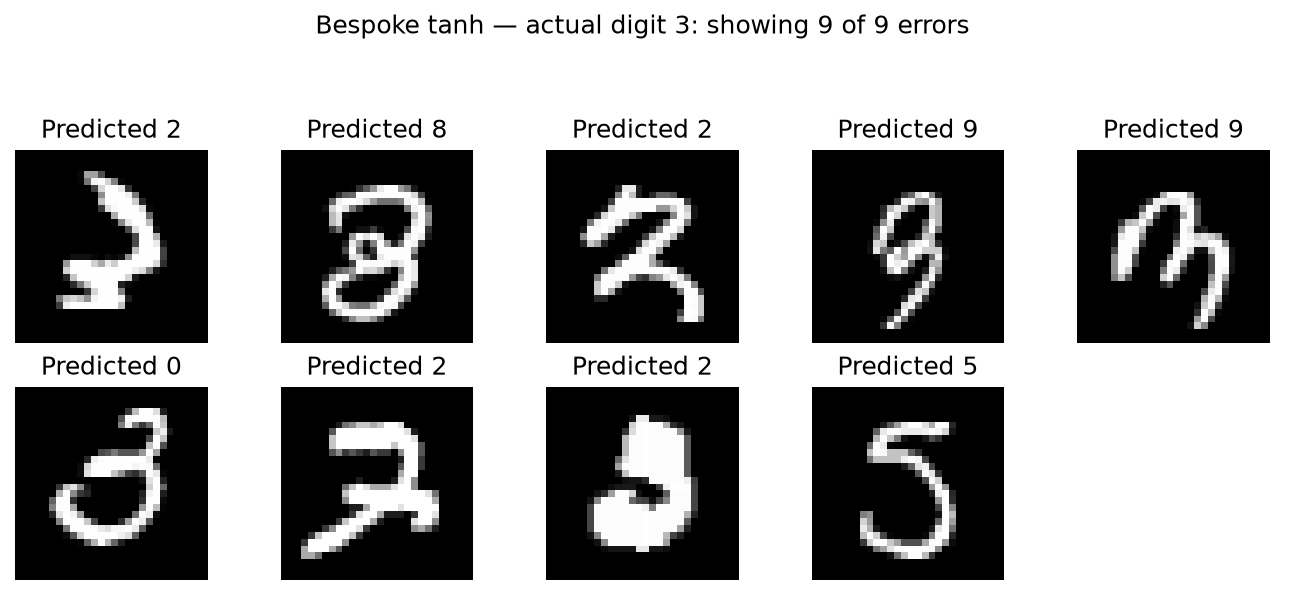

In [5]:
summary = []
histories = {}
for activation in ACTIVATIONS:
    display(Markdown(f"## Bespoke — {activation.upper()} results"))
    print(f"\nBespoke — {activation}")
    seed_training(SEED)
    train_loader, val_loader = build_data_loaders(
        train, validation_fraction=VALIDATION_FRACTION, batch_size=BATCH_SIZE, seed=SEED,
    )
    model_config = {"model_name": "bespoke", "activation": activation,
                    "upsample_mode": UPSAMPLE_MODE}
    model = build_model(**model_config)
    
    # Using reduction="none" will return a tensor containing the individual loss values,
    # one for each image in the batch. that let's us use .mean() for backpropagation 
    # and .sum() to accumulate the epoch's total loss.
    loss_function = torch.nn.CrossEntropyLoss(reduction="none")
    
    
    run_id = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
    checkpoint_path = project_root / "data" / "models" / f"bespoke_{activation}_{run_id}_best.pt"
    
    model, history, best_epoch, best_val_logits, best_val_labels = train_model(
        model, train_loader, val_loader, loss_function,
        epochs=EPOCHS, checkpoint_path=checkpoint_path,
        learning_rate=LEARNING_RATE,
    )
    
    # Keep each run's best validation outputs for comparison with future runs.
    validation_outputs_dir = project_root / "data" / "validation_outputs"
    validation_outputs_dir.mkdir(parents=True, exist_ok=True)
    validation_outputs_path = validation_outputs_dir / f"bespoke_{activation}_{run_id}_validation.pt"
    torch.save({
        "model_config": model_config,
        "training_config": {"seed": SEED, "validation_fraction": VALIDATION_FRACTION,
                            "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                            "epochs": EPOCHS, "optimizer": "Adam",
                            "checkpoint_selection": "lowest_validation_loss"},
        "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                        "numpy": np.__version__, "pandas": pd.__version__,
                        "sklearn": sklearn.__version__,
                        "device": str(next(model.parameters()).device)},
        "dataset_sha256": hashlib.sha256(
            train[["label", *PIXEL_COLUMNS]].to_numpy().tobytes()
        ).hexdigest(),
        "validation_sha256": hashlib.sha256(
            val_loader.dataset.tensors[0].numpy().tobytes()
            + val_loader.dataset.tensors[1].numpy().tobytes()
        ).hexdigest(),
        "history": history,
        "run_id": run_id,
        "checkpoint_path": str(checkpoint_path),
        "logits": best_val_logits.detach().cpu(),
        "labels": best_val_labels.detach().cpu(),
        "best_epoch": best_epoch,
        "seed": SEED,
        "validation_fraction": VALIDATION_FRACTION,
    }, validation_outputs_path)
    print(f"Validation outputs saved to: {validation_outputs_path}")
    
    history_df = pd.DataFrame(history)
    histories[activation] = history_df.copy()
    display(history_df)
    learning_fig = plot_training_history(history_df, best_epoch, chance_reference=0.10)
    display(learning_fig)
    plt.close(learning_fig)
    val_confusion_matrix, confusion_fig = plot_validation_confusion_matrix(model, val_loader)
    display(confusion_fig)
    plt.close(confusion_fig)
    per_digit_metrics = build_per_digit_metrics(val_confusion_matrix).sort_values("F1")
    display(per_digit_metrics)
    gallery_fig = plot_misclassified_digit(model, val_loader, digit=3, max_images=10)
    if gallery_fig is not None:
        display(gallery_fig)
        plt.close(gallery_fig)
    actual_digit, predicted_digit, scores = inspect_last_validation_prediction(
        best_val_logits, best_val_labels,
    )
    print(f"Actual digit: {actual_digit} | Predicted digit: {predicted_digit}")
    display(scores)
    summary.append({"activation": activation, "best_epoch": best_epoch,
                    "val_loss": history[best_epoch - 1]["val_loss"],
                    "val_accuracy": history[best_epoch - 1]["val_accuracy"],
                    "macro_f1": per_digit_metrics["F1"].mean(),
                    "validation_outputs": str(validation_outputs_path)})


In [6]:
display(pd.DataFrame(summary))


,activation,best_epoch,val_loss,val_accuracy,macro_f1,validation_outputs
0,relu,9,2.301173,0.111548,0.020071,/Users/KurtMeehanPro/Documents/code/git/digit-...
1,tanh,10,0.062895,0.982262,0.982189,/Users/KurtMeehanPro/Documents/code/git/digit-...


## Compare ReLU and tanh on shared axes

Color identifies activation; solid lines show training and dashed lines validation.
Both panels use the matched runs above.


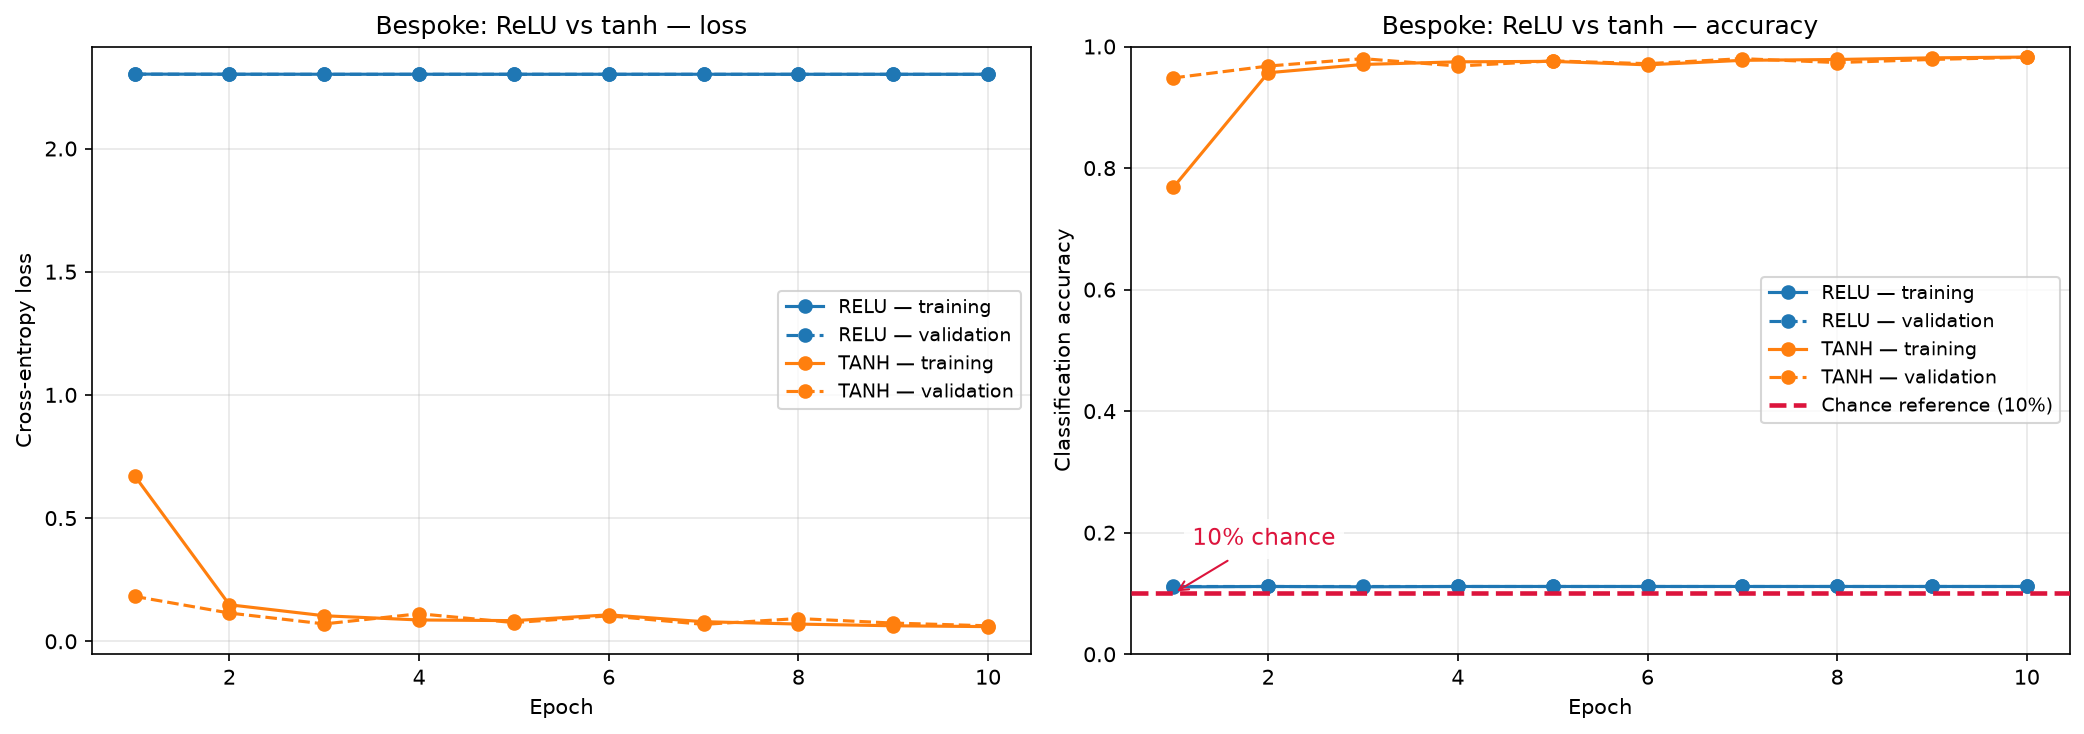

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for activation, color in zip(ACTIVATIONS, ("tab:blue", "tab:orange")):
    activation_history = histories[activation]
    for split, style in (("train", "-"), ("val", "--")):
        label = f"{activation.upper()} — {'training' if split == 'train' else 'validation'}"
        axes[0].plot(activation_history["epoch"], activation_history[f"{split}_loss"],
                     color=color, linestyle=style, marker="o", label=label)
        axes[1].plot(activation_history["epoch"], activation_history[f"{split}_accuracy"],
                     color=color, linestyle=style, marker="o", label=label)
axes[1].axhline(0.10, color="crimson", linestyle="--", linewidth=2.2,
                label="Chance reference (10%)", zorder=5)
axes[1].annotate("10% chance", xy=(1, 0.10), xytext=(1.2, 0.18), color="crimson",
                 arrowprops={"arrowstyle": "->", "color": "crimson"},
                 bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
axes[0].set(title="Bespoke: ReLU vs tanh — loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Bespoke: ReLU vs tanh — accuracy", xlabel="Epoch",
            ylabel="Classification accuracy", ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


## Results only — refresh completed runs without training

Run the next two cells to reload the plotting helpers and redisplay the completed
runs. These cells read saved histories, logits, and the original validation split;
they do not train or change the in-memory trained model/history variables.
The full training cell above is not needed. Both error galleries show at most ten
images. The first cell reloads modules and uses module-qualified calls, so stale
from-import aliases are avoided.


In [ ]:
import importlib
from pathlib import Path as ResultsPath
import hashlib as results_hashlib
import pandas as results_pd
import torch as results_torch
import matplotlib.pyplot as results_plt
from IPython.display import Markdown as ResultsMarkdown, display as results_display
import scripts.model.digit_model_helpers as results_model_helpers
import scripts.model.digit_model_metrics as results_metrics

results_model_helpers = importlib.reload(results_model_helpers)
results_metrics = importlib.reload(results_metrics)
results_root = ResultsPath(results_model_helpers.__file__).resolve().parents[2]
results_files = {
    "relu": results_root / "data/validation_outputs/bespoke_relu_20261029_220327_ba95689c_validation.pt",
    "tanh": results_root / "data/validation_outputs/bespoke_tanh_20261029_223450_f9e9ac62_validation.pt",
}
results_runs = {activation: results_torch.load(path, map_location="cpu", weights_only=True)
                for activation, path in results_files.items()}
results_frame = results_pd.read_csv(results_root / "data/raw/train.csv")
_, results_loader = results_model_helpers.build_data_loaders(
    results_frame, validation_fraction=0.2, batch_size=64, seed=42,
)
results_images, results_labels = results_loader.dataset.tensors
results_fingerprint = results_hashlib.sha256(
    results_images.numpy().tobytes() + results_labels.numpy().tobytes()
).hexdigest()
for results_run in results_runs.values():
    assert results_run["validation_sha256"] == results_fingerprint
    assert results_torch.equal(results_run["labels"], results_labels)


In [ ]:
for results_activation, results_run in results_runs.items():
    results_display(ResultsMarkdown(f"## Bespoke — {results_activation.upper()} results"))
    results_history = results_pd.DataFrame(results_run["history"])
    results_fig = results_model_helpers.plot_training_history(
        results_history, results_run["best_epoch"], chance_reference=0.10,
    )
    results_display(results_fig)
    results_plt.close(results_fig)
    results_gallery = results_metrics.plot_misclassified_digit(
        None, results_loader, digit=3, max_images=10,
        validation_logits=results_run["logits"],
    )
    if results_gallery is not None:
        results_display(results_gallery)
        results_plt.close(results_gallery)

results_display(ResultsMarkdown("## ReLU and tanh — shared comparison"))
results_fig, results_axes = results_plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for results_activation, results_color in (("relu", "tab:blue"), ("tanh", "tab:orange")):
    results_history = results_pd.DataFrame(results_runs[results_activation]["history"])
    for results_split, results_style in (("train", "-"), ("val", "--")):
        results_label = f"{results_activation.upper()} — {'training' if results_split == 'train' else 'validation'}"
        for results_ax, results_metric in zip(results_axes, ("loss", "accuracy")):
            results_ax.plot(results_history["epoch"], results_history[f"{results_split}_{results_metric}"],
                            color=results_color, linestyle=results_style, marker="o", label=results_label)
results_axes[0].set(title="Bespoke: ReLU vs tanh — loss", xlabel="Epoch", ylabel="Cross-entropy loss")
results_axes[1].set(title="Bespoke: ReLU vs tanh — accuracy", xlabel="Epoch",
                    ylabel="Classification accuracy", ylim=(0, 1))
results_axes[1].axhline(0.10, color="crimson", linestyle="--", linewidth=2.2,
                        label="Chance reference (10%)", zorder=5)
results_axes[1].annotate("10% chance", xy=(1, 0.10), xytext=(1.2, 0.18), color="crimson",
                         arrowprops={"arrowstyle": "->", "color": "crimson"})
for results_ax in results_axes:
    results_ax.grid(alpha=0.3)
    results_ax.legend()
results_fig.tight_layout()
results_display(results_fig)
results_plt.close(results_fig)
